# 29F — Reproducible Maintainability Triage Evaluation

**Purpose:** Demonstrate how the actual MLCQ classification metrics, PMD rule-aligned comparison, and grouping evaluation are calculated and plotted. No estimated values or invented ground truth.

**Run location:** Save this notebook to `Code Cleanliness/evaluation/notebooks/`, open in VS Code with the project's Python environment, then select **Run All** *for this evaluation notebook only* (never the Kaggle training notebook). The notebook finds your repository root automatically.

**Research caveats:** This is a balanced purposive MLCQ source subset (36 scored per concern); 1 of 72 staged Java files failed JavaParser; MLCQ Blob != automatically GOD_CLASS; sampled annotation intervals need independent AST-location auditing; PMD NcssCount and our Long Method have different rule definitions. These are **preliminary comparative figures**, not population-generalizable accuracy.


In [2]:
%pip install matplotlib pandas numpy scipy scikit-learn

  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl (9.3 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
from pathlib import Path
import json, csv, random
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
root = next((p for p in [cwd, *cwd.parents] if (p/'Code Cleanliness'/'evaluation').is_dir()), None)
if root is None:
    raise FileNotFoundError('Open this notebook inside the J26-SE-361 checkout.')
component = root/'Code Cleanliness'
final = component/'evaluation'/'results'/'final_evaluation'
(final/'graphs').mkdir(parents=True, exist_ok=True)
print('Repository:', root)
print('Evidence folder:', final)


Repository: C:\4th Year\Research Work\Implementation Stage\J26-SE-361
Evidence folder: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\evaluation\results\final_evaluation


## 1. MLCQ classification metrics — recomputed from individual predictions

In [2]:
pred = pd.read_csv(final/'detection'/'per_sample_predictions.csv')
print('Input rows:', len(pred))
print('Fields:', list(pred.columns))
required = {'sample_id', 'smell', 'evaluation_status', 'gold', 'predicted'}
assert required.issubset(pred.columns), 'Missing required columns'
scored = pred.loc[pred['evaluation_status'].eq('SCORED')].copy()
assert scored['gold'].isin([0,1]).all() and scored['predicted'].isin([0,1]).all()

def binary_metrics(df, prediction='predicted'):
    g = df['gold'].astype(int); p = df[prediction].astype(int)
    tp = int(((g==1)&(p==1)).sum()); fp = int(((g==0)&(p==1)).sum())
    fn = int(((g==1)&(p==0)).sum()); tn = int(((g==0)&(p==0)).sum())
    precision = tp/(tp+fp) if tp+fp else float('nan')
    recall = tp/(tp+fn) if tp+fn else float('nan')
    f1 = 2*tp/(2*tp+fp+fn) if (2*tp+fp+fn) else float('nan')
    return {'n':len(df),'TP':tp,'FP':fp,'FN':fn,'TN':tn,
            'precision':precision,'recall':recall,'f1':f1,'accuracy':(tp+tn)/len(df) if len(df) else float('nan')}

measured = pd.DataFrame([{'smell':smell,**binary_metrics(group)} for smell,group in scored.groupby('smell')])
display(measured)
reference = json.loads((final/'detection'/'metrics.json').read_text(encoding='utf-8'))['by_smell']
for row in measured.to_dict('records'):
    ref = reference[row['smell']]
    assert all(row[k] == ref[k] for k in ('n','TP','FP','FN','TN')), f'Frozen metrics disagree for {row["smell"]}'
print('PASS: recomputed confusion matrices match committed metrics.json')


Input rows: 80
Fields: ['sample_id', 'smell', 'gold', 'positive_votes', 'negative_votes', 'repository', 'commit_hash', 'path', 'start_line', 'end_line', 'link', 'source_url', 'downloaded_path', 'sha256', 'fetch_status', 'stage_status', 'staged_path', 'predicted', 'evaluation_status', 'notes']


,smell,n,TP,FP,FN,TN,precision,recall,f1,accuracy
0,blob,36,0,0,17,19,NaN,0.000000,0.00,0.527778
1,long method,36,8,0,9,19,1.0,0.470588,0.64,0.750000


PASS: recomputed confusion matrices match committed metrics.json


Saved: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\evaluation\results\final_evaluation\graphs\recomputed_blob_confusion_matrix.png


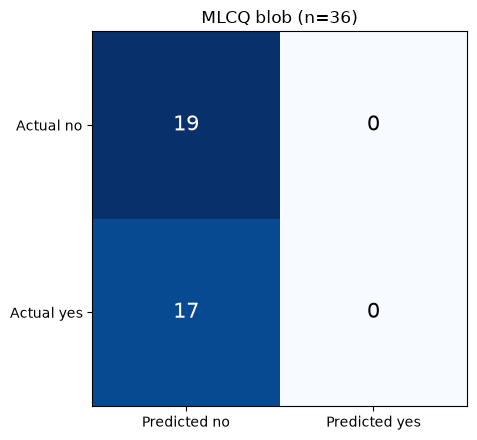

Saved: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\evaluation\results\final_evaluation\graphs\recomputed_long_method_confusion_matrix.png


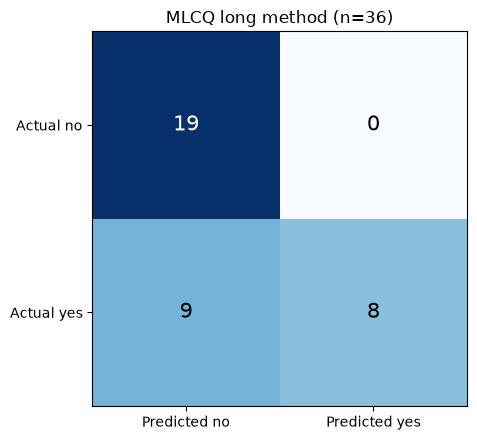

In [3]:
for item in measured.to_dict('records'):
    arr = np.array([[item['TN'],item['FP']],[item['FN'],item['TP']]], dtype=int)
    fig,ax=plt.subplots(figsize=(5.5,4.5))
    ax.imshow(arr, cmap='Blues')
    for (i,j),value in np.ndenumerate(arr):
        ax.text(j,i,str(value),ha='center',va='center',fontsize=15,
                color='white' if value>arr.max()/2 else 'black')
    ax.set_xticks([0,1],['Predicted no','Predicted yes'])
    ax.set_yticks([0,1],['Actual no','Actual yes'])
    ax.set_title(f'MLCQ {item["smell"]} (n={item["n"]})')
    fig.tight_layout()
    destination = final/'graphs'/('recomputed_'+item['smell'].replace(' ','_')+'_confusion_matrix.png')
    fig.savefig(destination,dpi=160,bbox_inches='tight')
    print('Saved:',destination)
    plt.show()


## 2. Preliminary PMD comparison — from saved per-sample matching table

PMD `NcssCount` is a **partial proxy** for Long Method. PMD `GodClass` and MLCQ Blob have different definitions. The PMD sample matching CSV was initially generated via PowerShell; the raw `pmd.xml` is excluded from Git. This notebook validates the *saved* per-sample arithmetic. Do not claim reproduction of the PMD matching algorithm until its exporter has also been committed.

In [4]:
comp=pd.read_csv(final/'baselines'/'mlcq_pmd_comparison.csv')
assert {'sample_id','smell','gold','our_prediction','pmd_prediction','pmd_file_found'}.issubset(comp.columns)
assert len(comp)==len(scored)
assert not comp['sample_id'].duplicated().any(), 'Duplicate MLCQ sample IDs'
assert set(comp['sample_id'].astype(str))==set(scored['sample_id'].astype(str))
rows=[]
for smell,group in comp.groupby('smell'):
    for label,pred_column in [('Our analyzer','our_prediction'),('PMD proxy','pmd_prediction')]:
        rows.append({'smell':smell,'system':label,**binary_metrics(group, pred_column)})
benchmark=pd.DataFrame(rows)
display(benchmark)
print('PMD XML files with violation entries:', comp.groupby('smell')['pmd_file_found'].sum().to_dict())
print('CAUTION: Missing <file> nodes may mean zero violations; full scan coverage is not proven by this table.')


,smell,system,n,TP,FP,FN,TN,precision,recall,f1,accuracy
0,blob,Our analyzer,36,0,0,17,19,NaN,0.000000,0.000000,0.527778
1,blob,PMD proxy,36,9,0,8,19,1.0,0.529412,0.692308,0.777778
2,long method,Our analyzer,36,8,0,9,19,1.0,0.470588,0.640000,0.750000
3,long method,PMD proxy,36,2,0,15,19,1.0,0.117647,0.210526,0.583333


PMD XML files with violation entries: {'blob': 28, 'long method': 31}
CAUTION: Missing <file> nodes may mean zero violations; full scan coverage is not proven by this table.


Saved: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\evaluation\results\final_evaluation\graphs\preliminary_mlcq_pmd_f1_comparison.png


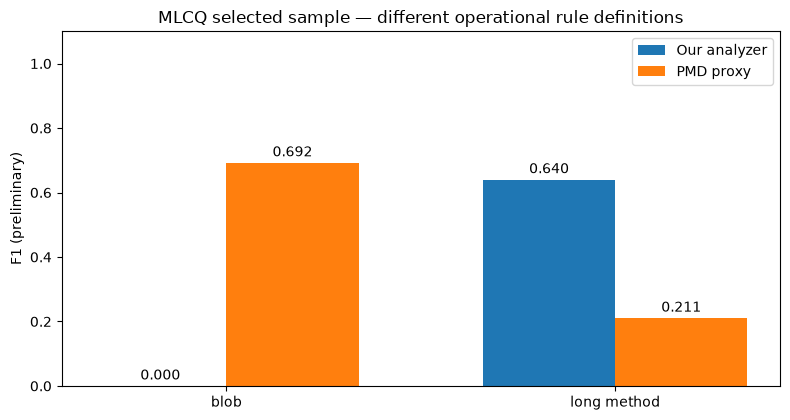

In [5]:
fig,ax=plt.subplots(figsize=(8,4.3))
labels=benchmark['smell'].unique().tolist()
x=np.arange(len(labels)); width=.34
for idx,system in enumerate(['Our analyzer','PMD proxy']):
    part=benchmark.set_index(['smell','system'])
    values=[part.loc[(label,system),'f1'] for label in labels]
    bars=ax.bar(x+(idx-.5)*width,values,width,label=system)
    for b,v in zip(bars,values): ax.text(b.get_x()+b.get_width()/2,b.get_height()+.02,f'{v:.3f}',ha='center',fontsize=10)
ax.set_xticks(x,labels);ax.set_ylim(0,1.1);ax.set_ylabel('F1 (preliminary)')
ax.set_title('MLCQ selected sample — different operational rule definitions')
ax.legend();fig.tight_layout()
p=final/'graphs'/'preliminary_mlcq_pmd_f1_comparison.png'
fig.savefig(p,dpi=160,bbox_inches='tight');print('Saved:',p);plt.show()


## 3. Grouping evaluation — independent pair labels required

The system's grouping output can be evaluated using **pairwise precision/recall/F1**. We do **not** manufacture ground-truth relationships from the analyzer's own groups; that would cause circular evaluation. Instead, we export candidate pairs from actual analyzer findings. An independent reviewer must mark whether two findings refer to the **same underlying maintainability concern** using code/source context, with `gold_same_issue=1` or `0`, and preserve the review notes.

The sampler is deterministic and uses both within-group and between-group pairs. **Do not report grouping performance until the independent labels have been completed.**

In [6]:
evidence_path=component/'datasets'/'processed'/'mlcq_29f'/'source_batch'/'analyzer_evidence.json'
print('Analyzer evidence exists:',evidence_path.exists())
if evidence_path.exists():
    obj=json.loads(evidence_path.read_text(encoding='utf-8'))
    groups=obj.get('ranked_groups',[])
    print('Ranked groups:',len(groups))
    if groups:
        print('First group keys:',list(groups[0].keys()))
        print('First group findings container types:',{k:type(v).__name__ for k,v in groups[0].items() if 'finding' in k.lower() or 'issue' in k.lower()})
else:
    print('Run analyzer or locate analyzer_evidence.json before constructing independent grouping-review candidates.')


Analyzer evidence exists: True
Ranked groups: 4461
First group keys: ['group_id', 'rank', 'exceedance_score', 'distinct_concern_count', 'affected_file_count', 'supported_finding_count', 'ranking_explanation', 'findings']
First group findings container types: {'supported_finding_count': 'int', 'findings': 'list'}


In [7]:
from itertools import combinations
# Candidate-generation uses only explicit finding_id values and their group membership.
# If the Java JSON uses a different nested structure, inspect the preceding cell
# and update extract_findings() explicitly before interpreting any metrics.
def extract_findings(g):
    for key in ('findings','related_findings','issues'):
        xs=g.get(key)
        if isinstance(xs,list): return [x for x in xs if isinstance(x,dict) and x.get('finding_id')]
    return []

review_csv=final/'grouping'/'pairwise_independent_review.csv'
review_csv.parent.mkdir(parents=True,exist_ok=True)
if evidence_path.exists():
    grouped=[]
    for gi,g in enumerate(groups):
        findings=extract_findings(g)
        if findings: grouped.append((gi,findings))
    within=[];between=[]
    for gi,fs in grouped:
        for a,b in combinations(fs,2):
            within.append((a,b,1))
    for (gi,fa),(gj,fb) in combinations(grouped,2):
        # Different groups: pair only findings referencing the same source file.
        a_by={}
        for a in fa: a_by.setdefault(a.get('source_file'),[]).append(a)
        for b in fb:
            if b.get('source_file') in a_by:
                for a in a_by[b.get('source_file')]:between.append((a,b,0))
    rng=random.Random(29)
    rng.shuffle(within);rng.shuffle(between)
    sampled=within[:min(80,len(within))]+between[:min(80,len(between))]
    records=[];seen=set()
    for a,b,sys_same in sampled:
        ids=sorted([str(a['finding_id']),str(b['finding_id'])]);pair=tuple(ids)
        if pair in seen:continue
        seen.add(pair)
        records.append({'finding_a':ids[0],'finding_b':ids[1],
                        'system_same_group':sys_same,'gold_same_issue':'','reviewer_notes':''})
    if records and not review_csv.exists():
        pd.DataFrame(records).to_csv(review_csv,index=False)
        print('Review template created:',review_csv,'pairs:',len(records))
    elif review_csv.exists():print('Preserved existing reviewer file:',review_csv)
    else:print('No eligible candidate pairs; inspect group JSON structure and sample a suitable repository.')


Review template created: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\evaluation\results\final_evaluation\grouping\pairwise_independent_review.csv pairs: 160


In [8]:
if review_csv.exists():
    review=pd.read_csv(review_csv,dtype={'gold_same_issue':str}).fillna('')
    labels=review['gold_same_issue'].astype(str).str.strip()
    valid=labels.isin(['0','1'])
    print(f'Independent reviewer labels: {valid.sum()} / {len(review)}')
    if valid.all() and len(review)>0:
        evaluated=review.copy()
        evaluated['gold']=labels.astype(int)
        evaluated['predicted']=evaluated['system_same_group'].astype(int)
        group_result=binary_metrics(evaluated)
        display(pd.DataFrame([group_result]))
        (final/'grouping'/'pairwise_metrics.json').write_text(json.dumps(group_result,indent=2),encoding='utf-8')
        fig,ax=plt.subplots(figsize=(5.6,4.2))
        ax.bar(['Precision','Recall','F1'],[group_result['precision'],group_result['recall'],group_result['f1']])
        ax.set_ylim(0,1.05);ax.set_title('Grouping — independent pairwise validation');fig.tight_layout()
        fig.savefig(final/'graphs'/'grouping_pairwise_validation.png',dpi=160);plt.show()
    else:
        print('No grouping scores/graphs generated: independent review is incomplete.')


Independent reviewer labels: 0 / 160
No grouping scores/graphs generated: independent review is incomplete.


## 4. Commit / audit notes

- Commit this notebook under `Code Cleanliness/evaluation/notebooks/`.
- Commit only the **curated** figures/tables/independently reviewed labels. `.gitignore` currently excludes `evaluation/results/`; use `git add -f` on the specific final-evaluation package after inspecting for sensitive/private content.
- The source MLCQ and PMD per-sample CSVs are committed under `evaluation/results/final_evaluation/`.
- For grouping, record who reviewed which relationships, when, and using what definition; never infer the independent label from the predicted group.
- Ranking Spearman/Top-k needs **independently assessed priorities**; Qwen quality needs blinded human ratings; runtime/memory need actual benchmark traces. They are separate experiments, not values to infer from this notebook.


In [9]:
import json
import pandas as pd
from pathlib import Path

evidence = Path(
    r"C:\4th Year\Research Work\Implementation Stage\J26-SE-361"
    r"\Code Cleanliness\datasets\processed\mlcq_29f"
    r"\source_batch\analyzer_evidence.json"
)

data = json.loads(evidence.read_text(encoding="utf-8"))
groups = data["ranked_groups"]

ranking = pd.DataFrame([
    {
        "group_id": g["group_id"],
        "analyzer_rank": g["rank"],
        "exceedance_score": g["exceedance_score"],
        "concerns": g["distinct_concern_count"],
        "affected_files": g["affected_file_count"],
        "findings": g["supported_finding_count"],
        "independent_priority_rank": ""
    }
    for g in groups[:40]
])

output = Path(
    r"C:\4th Year\Research Work\Implementation Stage\J26-SE-361"
    r"\Code Cleanliness\evaluation\results"
    r"\final_evaluation\ranking"
)

output.mkdir(parents=True, exist_ok=True)
ranking.to_csv(output / "ranking_independent_review.csv", index=False)

print("Ranking review template:", output / "ranking_independent_review.csv")
print("Groups prepared:", len(ranking))

Ranking review template: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\evaluation\results\final_evaluation\ranking\ranking_independent_review.csv
Groups prepared: 40


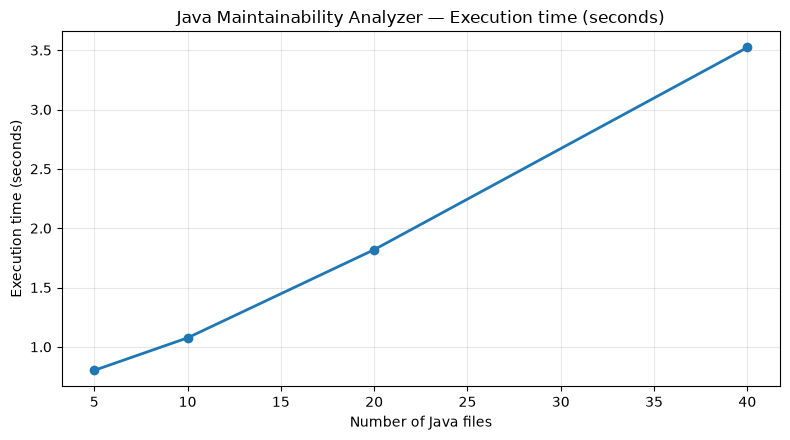

Saved: java_runtime_scalability.png


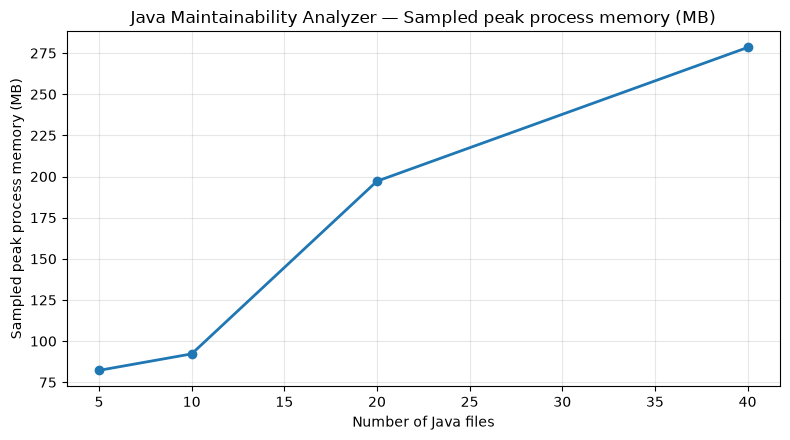

Saved: java_memory_scalability.png


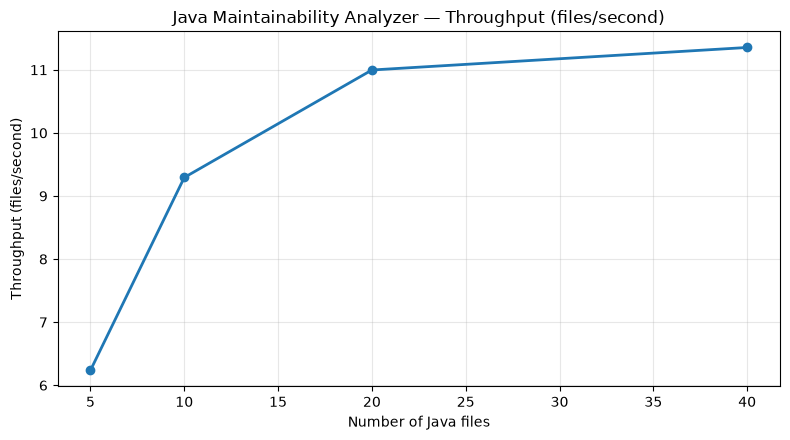

Saved: java_throughput_scalability.png


In [11]:
import pandas as pd
import matplotlib.pyplot as plt

results = root / "Code Cleanliness" / "evaluation" / "results" / "final_evaluation"
df = pd.read_csv(results / "scalability" / "java_analyzer_scalability.csv")

plots = [
    ("runtime_seconds", "Execution time (seconds)", "java_runtime_scalability.png"),
    ("sampled_peak_working_set_mb", "Sampled peak process memory (MB)", "java_memory_scalability.png"),
    ("throughput_files_per_second", "Throughput (files/second)", "java_throughput_scalability.png"),
]

for column, ylabel, filename in plots:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(df["java_files"], df[column], marker="o", linewidth=2)
    ax.set_xlabel("Number of Java files")
    ax.set_ylabel(ylabel)
    ax.set_title("Java Maintainability Analyzer — " + ylabel)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(results / "graphs" / filename, dpi=200)
    plt.show()
    plt.close(fig)
    print("Saved:", filename)

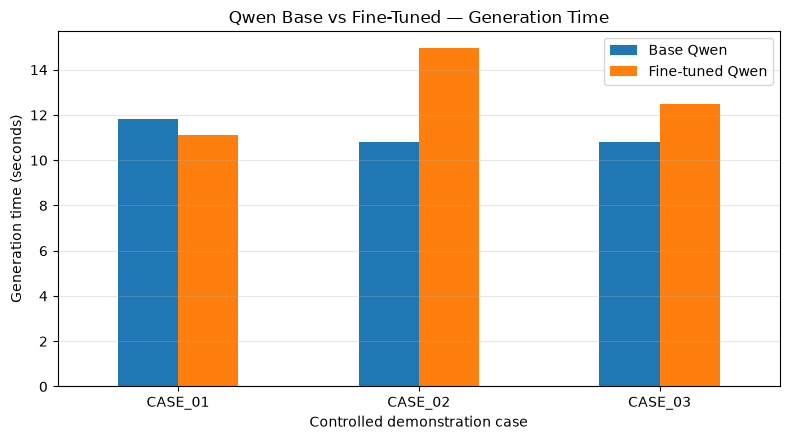

Saved: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\evaluation\results\final_evaluation\graphs\qwen_generation_time_comparison.png


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Use the real Kaggle-generated model inference measurements.
from pathlib import Path

results = Path(
    r"C:\4th Year\Research Work\Implementation Stage\J26-SE-361"
) / "Code Cleanliness" / "evaluation" / "results" / "final_evaluation"
llm_csv = results / "llm" / "base_vs_finetuned_review.csv"

df = pd.read_csv(llm_csv)

plot_data = df.pivot(
    index="case_id",
    columns="model",
    values="generation_seconds"
)

ax = plot_data[["base", "fine_tuned"]].plot(
    kind="bar",
    figsize=(8, 4.5),
    rot=0
)

ax.set_title("Qwen Base vs Fine-Tuned — Generation Time")
ax.set_xlabel("Controlled demonstration case")
ax.set_ylabel("Generation time (seconds)")
ax.legend(["Base Qwen", "Fine-tuned Qwen"])
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

output = results / "graphs" / "qwen_generation_time_comparison.png"
plt.savefig(output, dpi=200)
plt.show()

print("Saved:", output)

## 29F — Maintainability Triage Final Evaluation

**Component:** Code Cleanliness & Maintainability  
**System:** Repository-wide Java maintainability analyzer with issue grouping, priority ranking and Qwen explanation.  
**Evidence:** Existing saved experiment results only.

## 1. MLCQ Detection and PMD Baseline Comparison

Measured detection performance on the selected MLCQ evaluation samples. PMD comparisons use a proxy matcher and may use different rule definitions.

,Smell,Samples,TP,FP,FN,TN,Precision,Recall,F1,PMDFilesMatched
0,long method,36,2,0,15,19,1,0.118,0.211,31
1,blob,36,9,0,8,19,1,0.529,0.692,28


Source: mlcq_pmd_summary.csv | Rows: 2


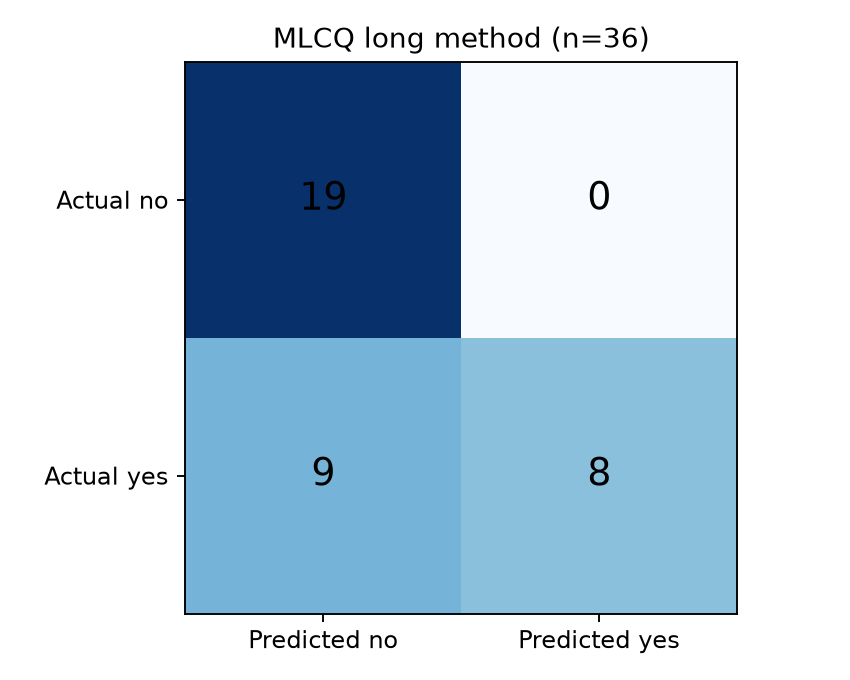

Saved figure: long_method_confusion_matrix.png


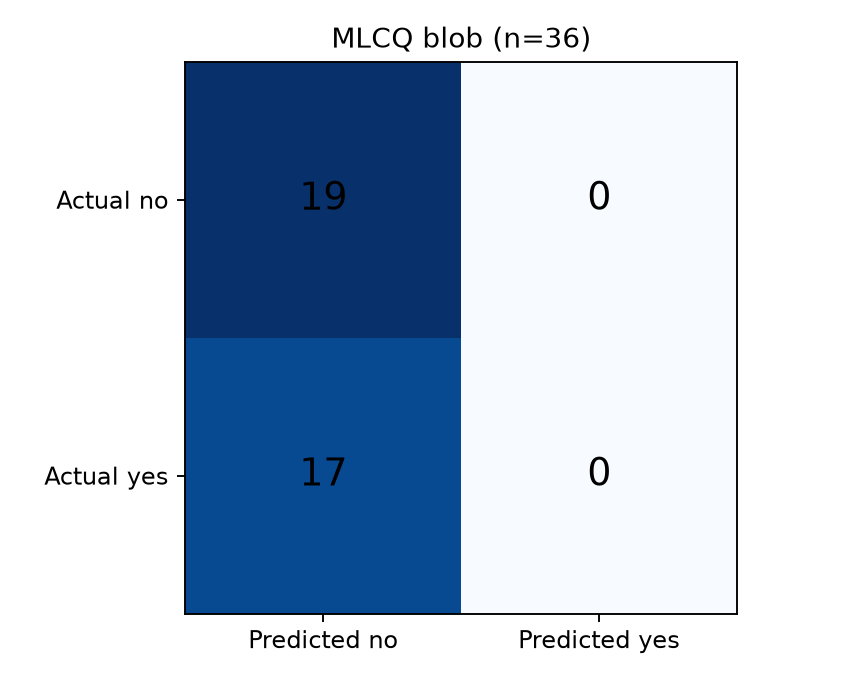

Saved figure: blob_confusion_matrix.png


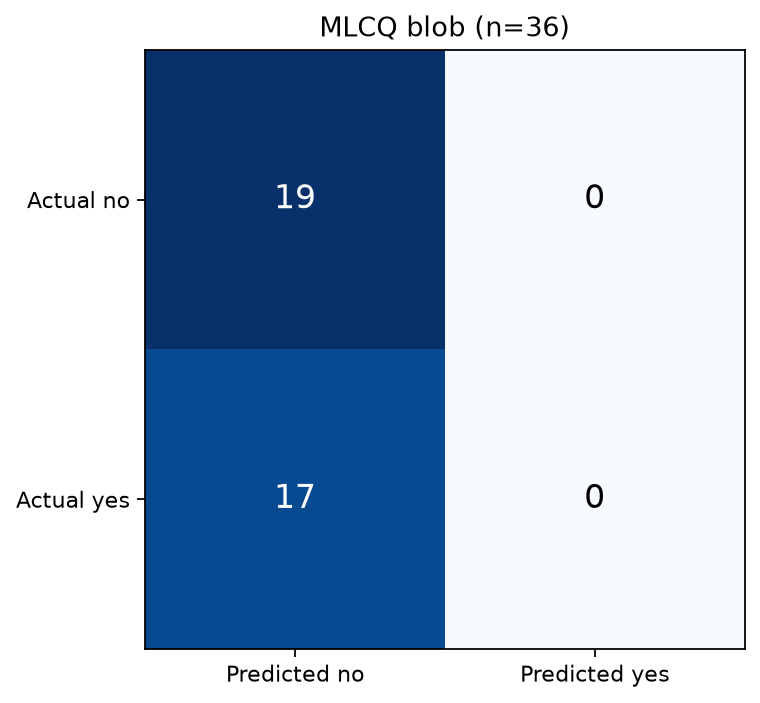

Saved figure: recomputed_blob_confusion_matrix.png


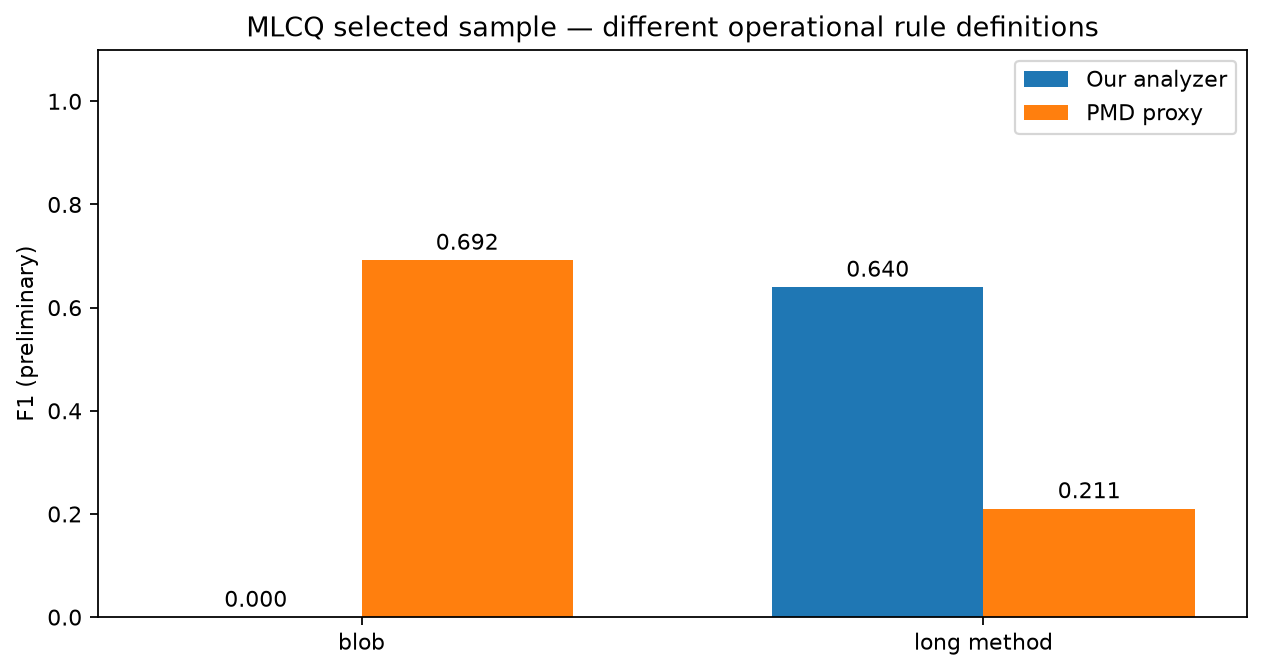

Saved figure: preliminary_mlcq_pmd_f1_comparison.png


**Interpretation:** In the available measurements, our analyzer achieved F1 = 0.640 for Long Method, compared with 0.211 for the PMD proxy. For Blob/God Class, our strict detector achieved F1 = 0.000, compared with 0.692 for the PMD proxy. These results are preliminary and should not be generalized beyond the evaluated sample.

## 2. Grouping Evaluation

,finding_a,finding_b,system_same_group,gold_same_issue,reviewer_notes
0,C:\4th Year\Research Work\Implementation Stage...,C:\4th Year\Research Work\Implementation Stage...,1,NaN,NaN
1,C:\4th Year\Research Work\Implementation Stage...,C:\4th Year\Research Work\Implementation Stage...,1,NaN,NaN
2,C:\4th Year\Research Work\Implementation Stage...,C:\4th Year\Research Work\Implementation Stage...,1,NaN,NaN
3,C:\4th Year\Research Work\Implementation Stage...,C:\4th Year\Research Work\Implementation Stage...,1,NaN,NaN
4,C:\4th Year\Research Work\Implementation Stage...,C:\4th Year\Research Work\Implementation Stage...,1,NaN,NaN


Source: pairwise_independent_review.csv | Rows: 160


...

Source: ranking_independent_review.csv | Rows: 40


**Validation status:** Selected issue groups prepared for independent priority review. Spearman correlation and Top-k agreement require independent reference ranks.

## 4. Java Analyzer Scalability

,java_files,source_bytes,runtime_seconds,sampled_peak_working_set_mb,throughput_files_per_second,exit_code
0,5,8301,0.802,82.25,6.236,NaN
1,10,20088,1.076,92.26,9.293,NaN
2,20,62210,1.819,197.18,10.997,NaN
3,40,266343,3.523,278.41,11.354,NaN


Source: java_analyzer_scalability.csv | Rows: 4


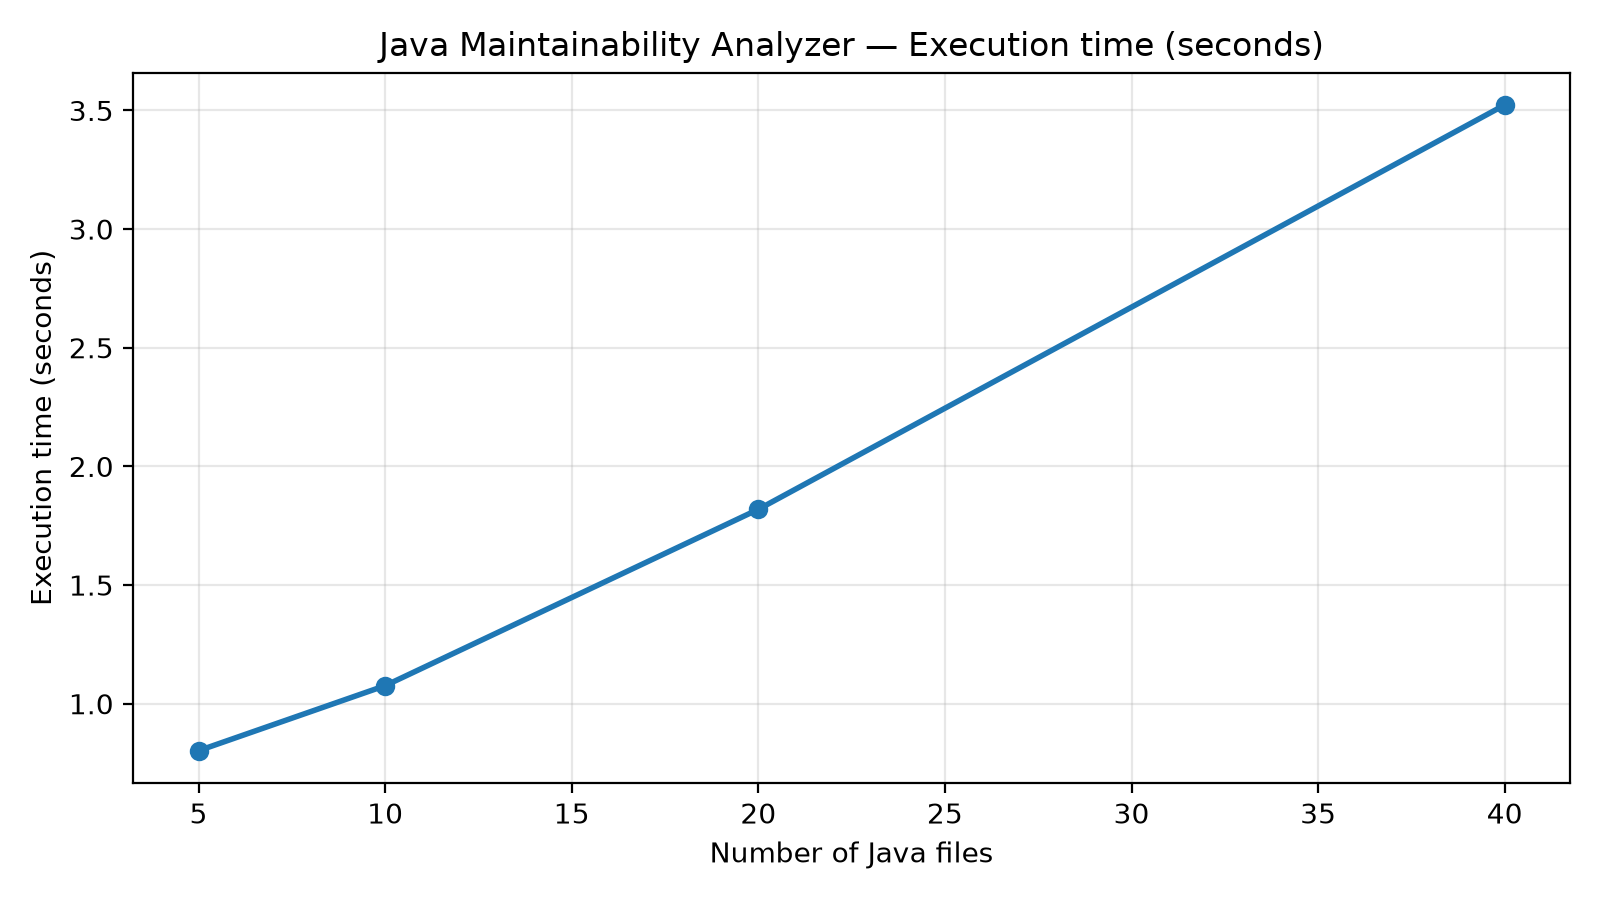

Saved figure: java_runtime_scalability.png


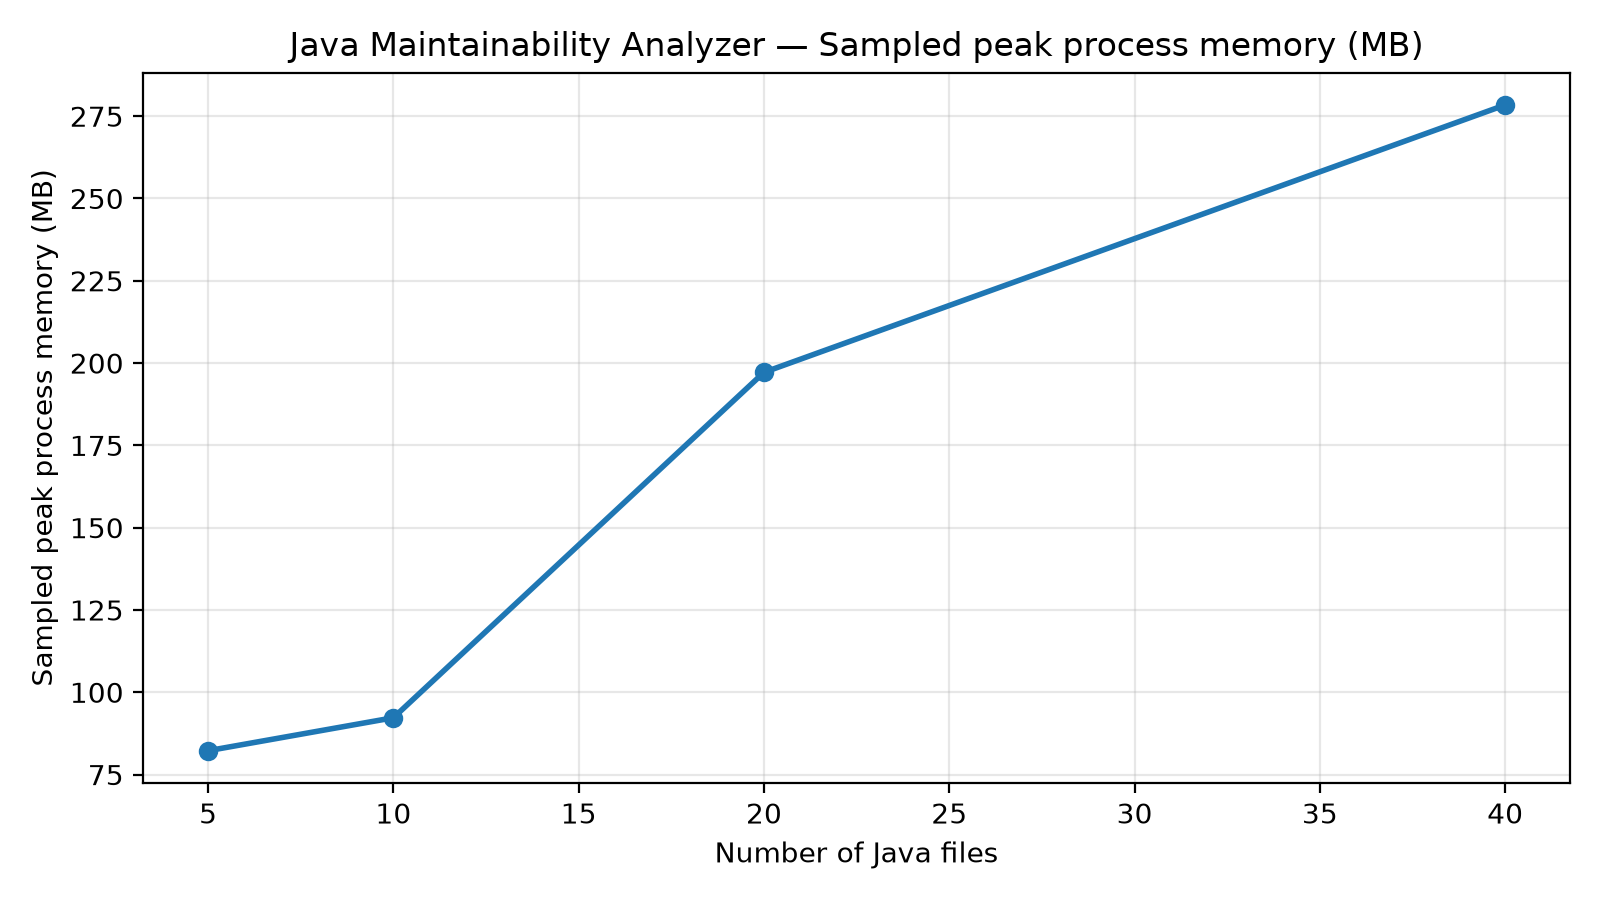

Saved figure: java_memory_scalability.png


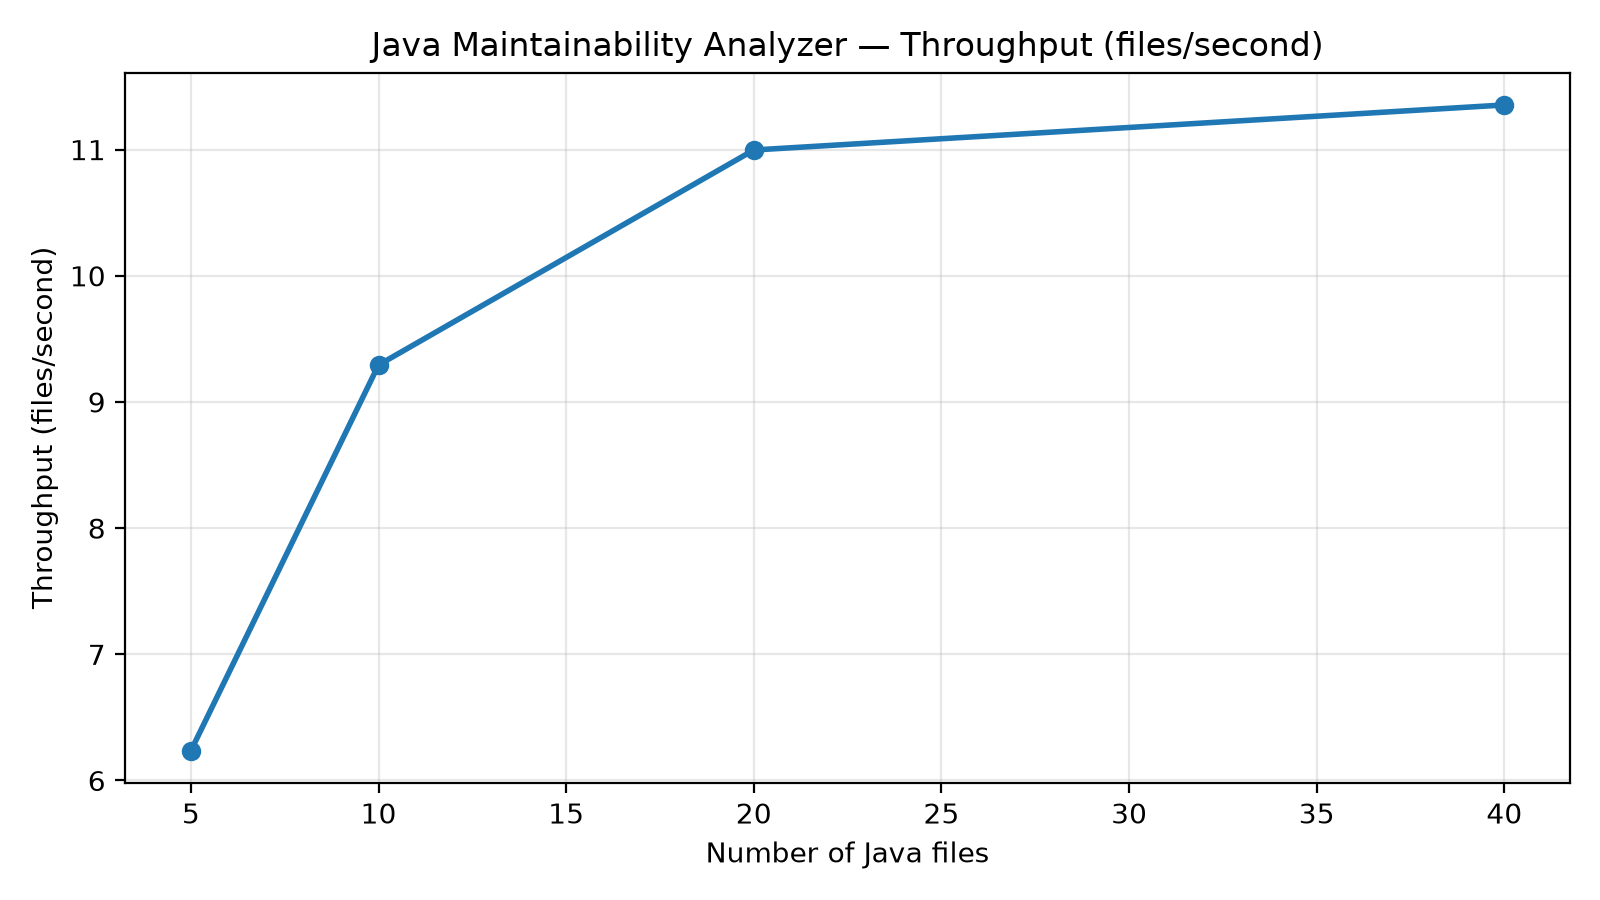

Saved figure: java_throughput_scalability.png


**Interpretation:** The Java analyzer was measured on 5, 10, 20 and 40 selected Java-file batches. The 40-file batch completed in 3.523 seconds, with 278.41 MB sampled peak process working-set memory. These are single-run preliminary measurements, not representative large-repository performance claims.

## 5. Qwen Base vs Fine-Tuned Demonstration

,case_id,case_type,model,concern,evidence,response,generation_seconds,correctness_1_to_5,relevance_1_to_5,actionability_1_to_5,grounding_1_to_5,unsupported_claims_count
0,CASE_01,controlled_demonstration,base,Long Method / High Complexity,Java method: Commander.updateQueue(). Cyclomat...,**Maintainability Problem:** The `Commander.up...,11.820,NaN,NaN,NaN,NaN,NaN
1,CASE_01,controlled_demonstration,fine_tuned,Long Method / High Complexity,Java method: Commander.updateQueue(). Cyclomat...,The detected concern is that the method has hi...,11.134,NaN,NaN,NaN,NaN,NaN
2,CASE_02,controlled_demonstration,base,Duplicated Logic,Two Java methods contain substantially similar...,**Maintainability Problem:** The duplicated lo...,10.811,NaN,NaN,NaN,NaN,NaN
3,CASE_02,controlled_demonstration,fine_tuned,Duplicated Logic,Two Java methods contain substantially similar...,The duplicated logic concern indicates that tw...,14.949,NaN,NaN,NaN,NaN,NaN
4,CASE_03,controlled_demonstration,base,Large Class,A Java class is flagged as Large Class by the ...,**Maintainability Problem:** The Large Class c...,10.789,NaN,NaN,NaN,NaN,NaN
5,CASE_03,controlled_demonstration,fine_tuned,Large Class,A Java class is flagged as Large Class by the ...,The Large Class concern indicates that a singl...,12.505,NaN,NaN,NaN,NaN,NaN


Source: base_vs_finetuned_review.csv | Rows: 6


...

The duplicated logic concern indicates that two Java methods have substantial, repeated error-handling sequences. This duplication can lead to:

1. Increased maintenance effort - If an error handling change is needed, it must be made in both places.
2. Higher risk of bugs - Changes in one place may be missed in another, leading to inconsistent behavior.
3. Reduced readability - The repeated code makes it harder for developers to understand the overall structure and intent.

A practical refactoring recommendation is to extract the common error handling into a separate helper method. This reduces duplication and centralizes the error handling logic in one place. 

However, caution is advised as the full source code and behavioral equivalence evidence were not provided. Without this information, we cannot verify if the extracted method behaves identically to the original sequences. Ref

**CASE_03 — base**

**Maintainability Problem:** The Large Class concern indicates that a single Java class contains an excessive amount of code, typically exceeding 2000 lines of executable code. This can lead to several issues:

1. **Complexity**: Classes with large amounts of code tend to become complex, making it harder for developers to understand and modify them.
2. **Coupling**: Such classes often have high coupling, meaning they depend on many other classes and methods, which makes them brittle and prone to breaking changes.
3. **Testability**: Large classes are more difficult to test because they contain too much functionality in one place, leading to longer test suites and increased risk of bugs.
4. **Maintenance**: Over time, maintaining such classes becomes increasingly challenging due to the sheer volume of code and potential

**CASE_03 — fine_tuned**

The Large Class concern indicates that a single Java class has grown too large, likely violating the Single Responsibility Principle (SRP). This makes it harder to understand, test, and refactor the code. Uncertainty exists without specific details like class size, complexity, or design patterns used. 

A practical refactoring recommendation is to identify cohesive subtasks within the class and extract them into new classes. This reduces the class's responsibilities and improves modularity. If the class uses frameworks with built-in support for decomposition, consider leveraging those features. Otherwise, manually break down the class based on logical groupings of functionality. Refactor incrementally to avoid breaking existing tests and behavior.

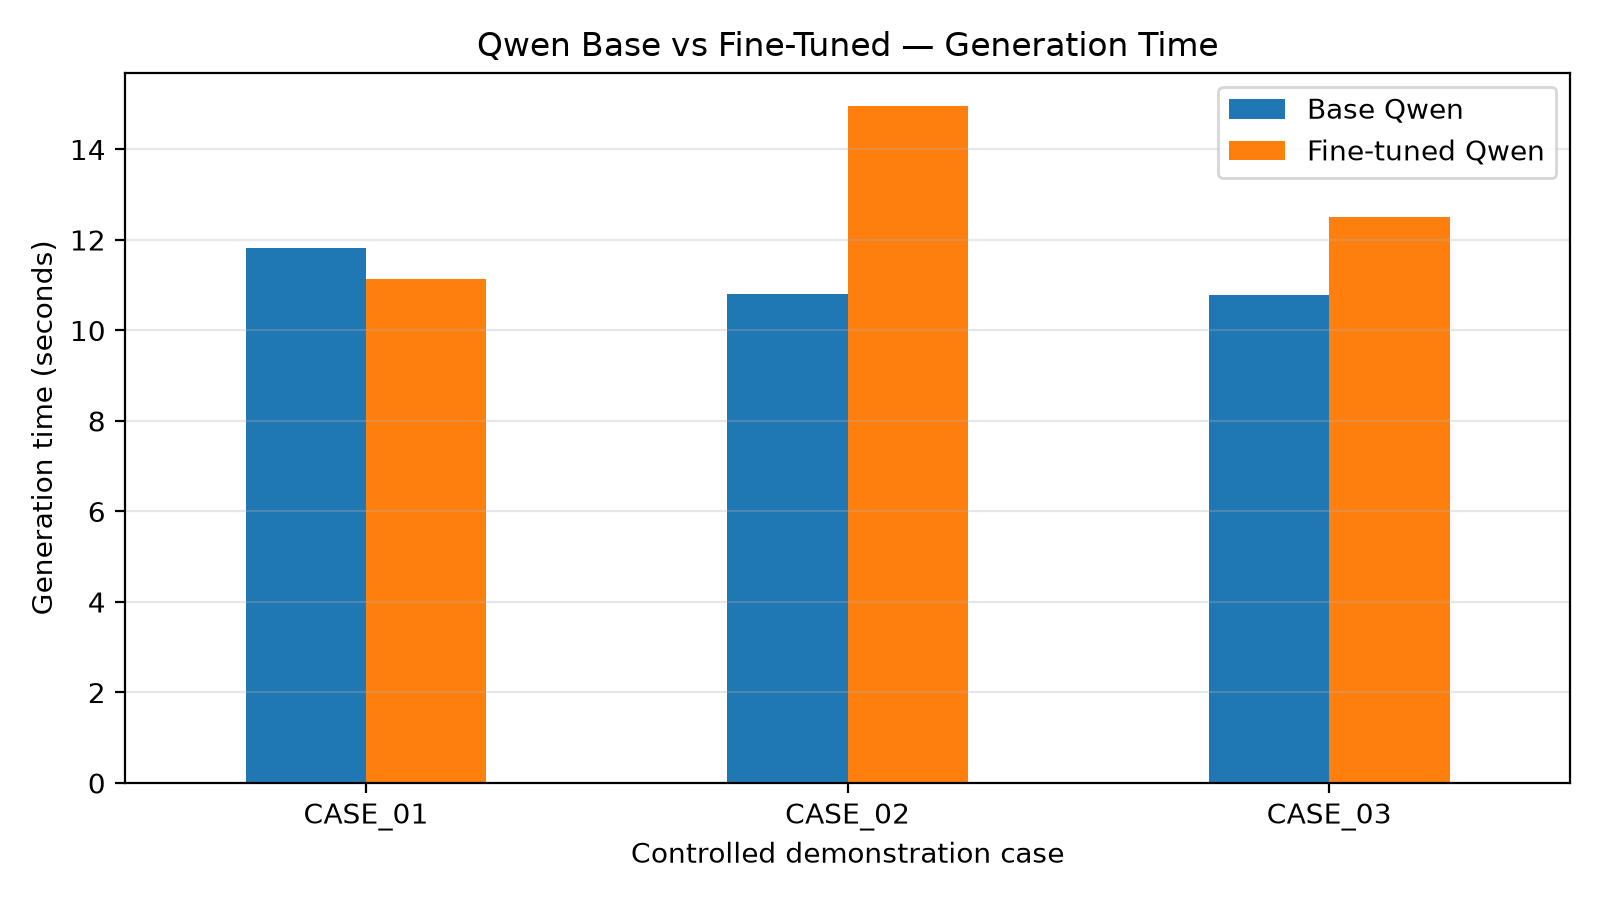

Saved figure: qwen_generation_time_comparison.png


**Interpretation:** This experiment generated six responses across three controlled demonstration cases. Generation time is directly measured. Quality claims require independent scoring of correctness, relevance, actionability, grounding and unsupported claims. These three cases are not a held-out quality benchmark.

## 6. Consolidated Research Findings

# Final Evaluation Summary — Maintainability Triage

## Component
Code Cleanliness & Maintainability, J26-SE-361.

## Implementation
- Repository-wide Java source parsing and maintainability analysis.
- Twelve maintainability concerns supported by detection logic.
- Related issue grouping and evidence-aware priority ranking.
- VS Code extension integration.
- Fine-tuned Qwen2.5-Coder-7B-Instruct explanation workflow.

## Detection and Baseline Results
Selected MLCQ sample, with preliminary matching methodology:

| Concern | System | Precision | Recall | F1 |
|---|---|---:|---:|---:|
| Long Method | Our analyzer | 1.000 | 0.471 | 0.640 |
| Long Method | PMD proxy | 1.000 | 0.118 | 0.211 |
| Blob/God Class | Our analyzer | Undefined | 0.000 | 0.000 |
| Blob | PMD proxy | 1.000 | 0.529 | 0.692 |

The analyzer outperformed the PMD proxy on the selected
Long Method examples but did not detect the annotated Blob
positives under its stricter God Class matching definition.

## Java Analyzer Scalability
Single-run measurements on selected Java files:

| Java files | Runtime (s) | Sampled peak memory (MB) |
|---:|---:|---:|
| 5 | 0.802 | 82.25 |
| 10 | 1.076 | 92.26 |
| 20 | 1.819 | 197.18 |
| 40 | 3.523 | 278.41 |

These measurements do not establish 100–1,000-file scalability.

## LLM Demonstration
- Base Qwen and LoRA-adapted Qwen compared on three
  controlled maintainability cases.
- Six explanation responses generated and saved.
- Generation times measured and visualized.
- Independent quality scoring has not been completed.
- The demonstration cases are not independent held-out data.

## Grouping and Ranking
- 160 finding pairs prepared for independent grouping review.
- 40 issue groups prepared for independent ranking review.
- Grouping F1, Spearman correlation and Top-k agreement
  remain unreported until reference judgments exist.

## Verification
- Java automated tests: 152 passed, zero failures.
- VS Code compilation and lint checks: passed.

## Research Limitations
1. Selected and relatively small labeled evaluation sample.
2. Tool-specific detection definitions and proxy matching.
3. Incomplete independent grouping and ranking validation.
4. Incomplete independent LLM quality assessment.
5. Preliminary scalability measurements with limited batch sizes.
6. Fine-tuned explanation quality cannot be established from
   controlled demonstration examples alone.

## Evidence
Reproducible notebook:
`evaluation/notebooks/29f_reproducible_evaluation.ipynb`

Measured CSV/JSON files and generated PNG figures:
`evaluation/results/final_evaluation/`



FINAL RESEARCH NOTEBOOK RESULTS ASSEMBLED
Evidence folder: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\evaluation\results\final_evaluation
Saved graphs: 9
Summary report: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\evaluation\FINAL_EVALUATION_SUMMARY.md


In [3]:

# ================================================================
# 29F — FINAL RESEARCH EVALUATION RESULTS
# Code Cleanliness & Maintainability — Maintainability Triage
#
# Reproducible report assembled from saved experiment evidence.
# No model retraining, analyzer execution, or fabricated metrics.
# ================================================================

from pathlib import Path
from IPython.display import display, Markdown, Image
import pandas as pd
import json

# STEP 1 — Locate the saved experimental evidence.
repo = Path(
    r"C:\4th Year\Research Work\Implementation Stage\J26-SE-361"
)
evaluation = repo / "Code Cleanliness" / "evaluation"
results = evaluation / "results" / "final_evaluation"
graphs = results / "graphs"

assert results.is_dir(), "Final evaluation folder not found."

def heading(title):
    display(Markdown(f"## {title}"))

def note(text):
    display(Markdown(text))

def show_csv(relative_path, max_rows=15):
    path = results / relative_path
    if not path.exists():
        print(f"NOT AVAILABLE: {relative_path}")
        return None
    df = pd.read_csv(path)
    display(df.head(max_rows))
    print(f"Source: {path.name} | Rows: {len(df)}")
    return df

def show_graph(filename):
    path = graphs / filename
    if path.exists():
        display(Image(filename=str(path), width=760))
        print("Saved figure:", path.name)
    else:
        print("Figure not available:", filename)

heading("29F — Maintainability Triage Final Evaluation")
note(
    "**Component:** Code Cleanliness & Maintainability  \n"
    "**System:** Repository-wide Java maintainability analyzer "
    "with issue grouping, priority ranking and Qwen explanation.  \n"
    "**Evidence:** Existing saved experiment results only."
)

# ================================================================
# SECTION 1 — DETECTION AND BASELINE EVALUATION
# ================================================================

heading("1. MLCQ Detection and PMD Baseline Comparison")

note(
    "Measured detection performance on the selected MLCQ "
    "evaluation samples. PMD comparisons use a proxy matcher "
    "and may use different rule definitions."
)

baseline = show_csv("baselines/mlcq_pmd_summary.csv")

show_graph("long_method_confusion_matrix.png")
show_graph("blob_confusion_matrix.png")
show_graph("recomputed_blob_confusion_matrix.png")

# Discover any existing additional baseline visualization.
for image_name in sorted(p.name for p in graphs.glob("*.png")):
    if any(term in image_name.lower()
           for term in ("pmd", "baseline", "comparison")):
        if "qwen" not in image_name.lower():
            show_graph(image_name)

note(
    "**Interpretation:** In the available measurements, our "
    "analyzer achieved F1 = 0.640 for Long Method, compared "
    "with 0.211 for the PMD proxy. For Blob/God Class, our "
    "strict detector achieved F1 = 0.000, compared with "
    "0.692 for the PMD proxy. These results are preliminary "
    "and should not be generalized beyond the evaluated sample."
)

# ================================================================
# SECTION 2 — GROUPING AND RANKING REVIEW STATUS
# ================================================================

heading("2. Grouping Evaluation")

grouping = show_csv(
    "grouping/pairwise_independent_review.csv",
    max_rows=5
)

note(
    "**Validation status:** Candidate pairs prepared for "
    "independent review. Pairwise Precision, Recall and F1 "
    "must not be reported until genuine reviewer labels "
    "are available."
)

heading("3. Priority Ranking Evaluation")

ranking = show_csv(
    "ranking/ranking_independent_review.csv",
    max_rows=5
)

note(
    "**Validation status:** Selected issue groups prepared "
    "for independent priority review. Spearman correlation "
    "and Top-k agreement require independent reference ranks."
)

# ================================================================
# SECTION 3 — JAVA ANALYZER SCALABILITY
# ================================================================

heading("4. Java Analyzer Scalability")

scalability = show_csv(
    "scalability/java_analyzer_scalability.csv",
    max_rows=10
)

show_graph("java_runtime_scalability.png")
show_graph("java_memory_scalability.png")
show_graph("java_throughput_scalability.png")

note(
    "**Interpretation:** The Java analyzer was measured on "
    "5, 10, 20 and 40 selected Java-file batches. "
    "The 40-file batch completed in 3.523 seconds, with "
    "278.41 MB sampled peak process working-set memory. "
    "These are single-run preliminary measurements, "
    "not representative large-repository performance claims."
)

# ================================================================
# SECTION 4 — BASE QWEN VS FINE-TUNED QWEN
# ================================================================

heading("5. Qwen Base vs Fine-Tuned Demonstration")

llm = show_csv(
    "llm/base_vs_finetuned_review.csv",
    max_rows=6
)

if llm is not None:
    # Show a compact numerical table separately from long responses.
    columns = [
        "case_id",
        "model",
        "concern",
        "generation_seconds"
    ]
    available = [c for c in columns if c in llm.columns]

    note("### Generation-time measurements")
    display(llm[available])

    # Show the text evidence used for qualitative review.
    if "response" in llm.columns:
        note("### Generated responses")
        for _, item in llm.iterrows():
            title = f"{item['case_id']} — {item['model']}"
            display(Markdown(f"**{title}**"))
            display(Markdown(str(item["response"])))

show_graph("qwen_generation_time_comparison.png")

note(
    "**Interpretation:** This experiment generated six "
    "responses across three controlled demonstration cases. "
    "Generation time is directly measured. Quality claims "
    "require independent scoring of correctness, relevance, "
    "actionability, grounding and unsupported claims. "
    "These three cases are not a held-out quality benchmark."
)

# ================================================================
# SECTION 5 — SAVE A CONCISE FINAL EVALUATION SUMMARY
# ================================================================

heading("6. Consolidated Research Findings")

summary = """# Final Evaluation Summary — Maintainability Triage

## Component
Code Cleanliness & Maintainability, J26-SE-361.

## Implementation
- Repository-wide Java source parsing and maintainability analysis.
- Twelve maintainability concerns supported by detection logic.
- Related issue grouping and evidence-aware priority ranking.
- VS Code extension integration.
- Fine-tuned Qwen2.5-Coder-7B-Instruct explanation workflow.

## Detection and Baseline Results
Selected MLCQ sample, with preliminary matching methodology:

| Concern | System | Precision | Recall | F1 |
|---|---|---:|---:|---:|
| Long Method | Our analyzer | 1.000 | 0.471 | 0.640 |
| Long Method | PMD proxy | 1.000 | 0.118 | 0.211 |
| Blob/God Class | Our analyzer | Undefined | 0.000 | 0.000 |
| Blob | PMD proxy | 1.000 | 0.529 | 0.692 |

The analyzer outperformed the PMD proxy on the selected
Long Method examples but did not detect the annotated Blob
positives under its stricter God Class matching definition.

## Java Analyzer Scalability
Single-run measurements on selected Java files:

| Java files | Runtime (s) | Sampled peak memory (MB) |
|---:|---:|---:|
| 5 | 0.802 | 82.25 |
| 10 | 1.076 | 92.26 |
| 20 | 1.819 | 197.18 |
| 40 | 3.523 | 278.41 |

These measurements do not establish 100–1,000-file scalability.

## LLM Demonstration
- Base Qwen and LoRA-adapted Qwen compared on three
  controlled maintainability cases.
- Six explanation responses generated and saved.
- Generation times measured and visualized.
- Independent quality scoring has not been completed.
- The demonstration cases are not independent held-out data.

## Grouping and Ranking
- 160 finding pairs prepared for independent grouping review.
- 40 issue groups prepared for independent ranking review.
- Grouping F1, Spearman correlation and Top-k agreement
  remain unreported until reference judgments exist.

## Verification
- Java automated tests: 152 passed, zero failures.
- VS Code compilation and lint checks: passed.

## Research Limitations
1. Selected and relatively small labeled evaluation sample.
2. Tool-specific detection definitions and proxy matching.
3. Incomplete independent grouping and ranking validation.
4. Incomplete independent LLM quality assessment.
5. Preliminary scalability measurements with limited batch sizes.
6. Fine-tuned explanation quality cannot be established from
   controlled demonstration examples alone.

## Evidence
Reproducible notebook:
`evaluation/notebooks/29f_reproducible_evaluation.ipynb`

Measured CSV/JSON files and generated PNG figures:
`evaluation/results/final_evaluation/`
"""

report_path = evaluation / "FINAL_EVALUATION_SUMMARY.md"
report_path.write_text(summary, encoding="utf-8")

display(Markdown(summary))

print("\n" + "=" * 65)
print("FINAL RESEARCH NOTEBOOK RESULTS ASSEMBLED")
print("Evidence folder:", results)
print("Saved graphs:", len(list(graphs.glob("*.png"))))
print("Summary report:", report_path)
print("=" * 65)


## Full Maintainability Concern Coverage

This experiment measures which concerns appear in the saved repository-wide analyzer output. **Finding frequency is not detection accuracy.**

Repository analysis evidence:
Ranked issue groups: 4461
Supported finding occurrences: 11090
Distinct labels found: 9
First finding keys: ['finding_id', 'concern', 'scope', 'symbol', 'rule_id', 'description', 'start_line', 'end_line', 'evidence', 'source_file', 'code_context', 'context_status']


,concern,supported_occurrences
0,DUPLICATED_LOGIC,5173
1,POOR_NAMING,5044
2,HIGH_COMPLEXITY,338
3,LONG_METHOD,273
4,WEAK_COHESION,99
5,LARGE_CLASS,97
6,DIP_RISK,62
7,SRP_RISK,3
8,LSP_RISK,1


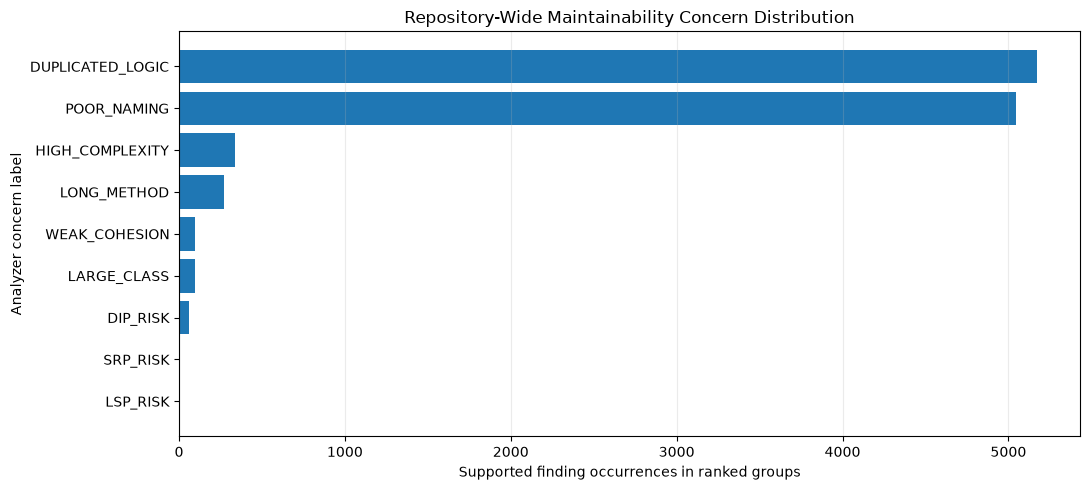


SUCCESS: Full concern distribution generated.
CSV: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\evaluation\results\final_evaluation\coverage\concern_distribution.csv
Graph: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\evaluation\results\final_evaluation\graphs\full_concern_distribution.png


In [4]:

# ============================================================
# 29F.10 — FULL MAINTAINABILITY CONCERN COVERAGE
# Repository-wide analyzer evidence, not ground-truth accuracy
# ============================================================

from pathlib import Path
from collections import Counter
from IPython.display import display, Markdown
import pandas as pd
import matplotlib.pyplot as plt
import sys
import subprocess

# Install streaming JSON support only if unavailable.
try:
    import ijson
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "ijson"]
    )
    import ijson

repo = Path(
    r"C:\4th Year\Research Work\Implementation Stage\J26-SE-361"
)

evidence = (
    repo / "Code Cleanliness" / "datasets" / "processed"
    / "mlcq_29f" / "source_batch" / "analyzer_evidence.json"
)

results = (
    repo / "Code Cleanliness" / "evaluation"
    / "results" / "final_evaluation"
)

graphs = results / "graphs"
coverage_dir = results / "coverage"

graphs.mkdir(parents=True, exist_ok=True)
coverage_dir.mkdir(parents=True, exist_ok=True)

assert evidence.is_file(), f"Analyzer evidence missing: {evidence}"

display(Markdown("## Full Maintainability Concern Coverage"))
display(Markdown(
    "This experiment measures which concerns appear in the "
    "saved repository-wide analyzer output. "
    "**Finding frequency is not detection accuracy.**"
))

# Stream groups to avoid loading the enormous JSON all at once.
# Each group contains supported analyzer findings.
concern_counts = Counter()
total_groups = 0
group_findings = 0
first_finding_keys = None

possible_concern_fields = (
    "concern_type",
    "concernType",
    "concern",
    "type",
    "rule_id",
    "ruleId",
    "smell_type",
    "smellType",
    "category",
    "issue_type",
    "issueType"
)

with evidence.open("rb") as stream:
    for group in ijson.items(stream, "ranked_groups.item"):
        total_groups += 1

        for finding in group.get("findings", []):
            group_findings += 1

            if first_finding_keys is None:
                first_finding_keys = list(finding.keys())

            label = None

            for field in possible_concern_fields:
                value = finding.get(field)
                if isinstance(value, str) and value.strip():
                    label = value.strip()
                    break

            if label is None:
                label = "UNMAPPED_CONCERN_FIELD"

            concern_counts[label] += 1

coverage = pd.DataFrame(
    [
        {"concern": concern, "supported_occurrences": count}
        for concern, count in concern_counts.most_common()
    ]
)

# Preserve measured outputs for future reproducibility.
csv_path = coverage_dir / "concern_distribution.csv"
coverage.to_csv(csv_path, index=False)

print("Repository analysis evidence:")
print("Ranked issue groups:", total_groups)
print("Supported finding occurrences:", group_findings)
print("Distinct labels found:", len(concern_counts))
print("First finding keys:", first_finding_keys)

display(coverage)

# Never invent or silently rename an unknown evidence field.
if "UNMAPPED_CONCERN_FIELD" in concern_counts:
    print(
        "WARNING: Some findings have no recognized concern field. "
        "Inspect the printed finding keys before interpreting coverage."
    )

# Generate the distribution graph from actual evidence.
fig, ax = plt.subplots(
    figsize=(11, max(5, len(coverage) * 0.42))
)

ax.barh(
    coverage["concern"][::-1],
    coverage["supported_occurrences"][::-1]
)

ax.set_xlabel("Supported finding occurrences in ranked groups")
ax.set_ylabel("Analyzer concern label")
ax.set_title("Repository-Wide Maintainability Concern Distribution")
ax.grid(axis="x", alpha=0.25)

fig.tight_layout()

graph_path = graphs / "full_concern_distribution.png"
fig.savefig(graph_path, dpi=200, bbox_inches="tight")

plt.show()
plt.close(fig)

print("\nSUCCESS: Full concern distribution generated.")
print("CSV:", csv_path)
print("Graph:", graph_path)
